# Observational selection sensitivity: OLS, HAC, and BH
Run the cells one by one. Start with the final window, inspect changes, then enable the full run.
This notebook uses **real annual records**, not synthetic simulations. It has its own kernel and requires no variables from another notebook.

Defaults reproduce the supplied settings: 70 years, 87% completeness, two-sided $p\le0.01$, 25% upper-tail trimming, 1000 half-samples without replacement, median of subsample medians.
NumPy, SciPy, pandas and Matplotlib are required. The original reader is embedded. Statistical checks against statsmodels are optional.


## 1. Configuration
Set `DATA_DIR` to the PSMSL annual folder containing `filelist.txt` and `data/`.
`hac_lag=3` uses three calendar-year lags; Section 7 checks 1, 3, 5 and 10. This is a sensitivity setting, not an empirically calibrated optimal bandwidth.
Use `window_length=60` for the other Figure 9 panel; use `completeness=0.75` for the original completeness comparison. Rerun from this cell after changes. Checkpoints separate configurations automatically.


In [1]:
from pathlib import Path
import os, glob, io, json, hashlib
import numpy as np
import scipy
from scipy import stats
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path('../data/rlr_annual')
OUTPUT_DIR = Path('observational_hac_results')
CONFIG = dict(year_limits=[1900,2019], window_length=70, completeness=0.87,
              pcrit=0.01, fdr_q=0.01, hac_lag=3, gammas=[0.0,0.10,0.25],
              sample_fraction=0.5, repetitions=1000, seed=2027)
FINAL_START = CONFIG['year_limits'][1]-CONFIG['window_length']+1
print('Final window:', FINAL_START, 'to', CONFIG['year_limits'][1])
print('Data directory:', DATA_DIR.resolve())
print(CONFIG)


Final window: 1950 to 2019
Data directory: C:\Users\User\work\IPGP\Climate\data\rlr_annual
{'year_limits': [1900, 2019], 'window_length': 70, 'completeness': 0.87, 'pcrit': 0.01, 'fdr_q': 0.01, 'hac_lag': 3, 'gammas': [0.0, 0.1, 0.25], 'sample_fraction': 0.5, 'repetitions': 1000, 'seed': 2027}


## 2. Statistical definitions
All three methods fit the same intercept and OLS slope; only inference and selection change.

- **OLS:** conventional two-sided Student $t$ p-value, followed by positive-slope selection.
- **HAC:** Bartlett/Newey–West covariance using calendar-year lags and finite-sample multiplier $n/(n-2)$. P-values use $t_{n-2}$ as an approximation, not an exact finite-sample HAC test.
- **HAC_BH:** Benjamini–Hochberg adjustment of HAC p-values across **all completeness-qualified stations**, before the positive-slope filter, at $q=0.01$.

Missing observations are omitted from regression. For HAC covariance, their score contributions are zero on the full annual grid, so observations separated by a gap are not treated as consecutive years. Observed values are not interpolated. This implements calendar-lag score covariance conditional on the observed sampling pattern; it does not model the missingness mechanism.

BH is a multiple-testing sensitivity analysis. Its usual FDR guarantee requires independence or suitable positive dependence, which this notebook does not establish for tide gauges. Annual data can still have serially correlated residuals. HAC SEs can increase or decrease relative to OLS.

References: [statsmodels HAC documentation](https://www.statsmodels.org/stable/generated/statsmodels.stats.sandwich_covariance.cov_hac.html), [multiple-testing documentation](https://www.statsmodels.org/stable/generated/statsmodels.stats.multitest.multipletests.html).


## 3. Functions (run once)
The reader and completeness rules match the supplied Python files. Quality flags are read but **not used to remove records**, matching the previous workflow. Station records must span the whole window. Missing heights are NaN or -99999.
MATLAB positive-number rounding is retained. Python random draws reproduce the estimator, not MATLAB's exact random stream. The old global 99% error-bar construction is not reproduced; `subsample_sd` is a conditional resampling SD, not a confidence interval.


In [2]:
import os
import glob
import numpy as np


def read_annual(directory_name):
    """
    Reads PSMSL RLR annual data directory.
    
    Parameters:
        directory_name (str): Path to unzipped PSMSL directory containing 
                              'filelist.txt' and the 'data/' folder.
                              
    Returns:
        list of dict: Each dict corresponds to a station with keys:
            'id', 'latitude', 'longitude', 'name', 'coastline',
            'stationcode', 'stationflag', 'year', 'height',
            'interpolated', 'isMtl', 'dataflag'
    """
    if not os.path.isdir(directory_name):
        raise FileNotFoundError(f"Cannot find directory: {directory_name}")

    data_dir = os.path.join(directory_name, 'data')
    if not os.path.isdir(data_dir):
        raise FileNotFoundError(
            f"Cannot find data directory {data_dir}. "
            "Please ensure the path points to the root unzipped folder, not 'data/' itself."
        )

    # 1. Parse filelist.txt catalogue
    cat_file = os.path.join(directory_name, 'filelist.txt')
    if not os.path.isfile(cat_file):
        raise FileNotFoundError(f"Could not find catalogue file: {cat_file}")

    catalogue = {}
    with open(cat_file, 'r', encoding='utf-8', errors='ignore') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            parts = line.split(';')
            if len(parts) < 7:
                continue
            st_id = int(parts[0].strip())
            catalogue[st_id] = {
                'latitude': float(parts[1].strip()),
                'longitude': float(parts[2].strip()),
                'name': parts[3].strip(),
                'coastline': int(parts[4].strip()) if parts[4].strip() else None,
                'stationcode': int(parts[5].strip()) if parts[5].strip() else None,
                'stationflag': parts[6].strip() == 'Y'
            }

    # 2. Match .rlrdata files
    file_paths = glob.glob(os.path.join(data_dir, '*.rlrdata'))
    data = []

    for path in sorted(file_paths):
        filename = os.path.basename(path)
        st_id = int(filename.split('.')[0])
        
        meta = catalogue.get(st_id, {
            'latitude': np.nan, 'longitude': np.nan, 'name': '',
            'coastline': None, 'stationcode': None, 'stationflag': False
        })

        # 3. Read station time series
        # Format: Year; Height; InterpolatedFlag; QualityFlags(3 digits)
        years, heights, interpolated, is_mtl, dataflag = [], [], [], [], []
        
        with open(path, 'r', encoding='utf-8', errors='ignore') as f:
            for line in f:
                line = line.strip()
                if not line:
                    continue
                parts = line.split(';')
                if len(parts) < 4:
                    continue

                yr = int(parts[0].strip())
                raw_h = float(parts[1].strip())
                h = np.nan if raw_h == -99999 else raw_h
                interp = parts[2].strip() == 'Y'

                # Flags: 3-character string (e.g. "000")
                flags_str = parts[3].strip()
                flags_str = flags_str.ljust(3, '0')
                mtl = flags_str[1] == '1'
                dflag = flags_str[2] == '1'

                years.append(yr)
                heights.append(h)
                interpolated.append(interp)
                is_mtl.append(mtl)
                dataflag.append(dflag)

        station_record = {
            'id': st_id,
            'latitude': meta['latitude'],
            'longitude': meta['longitude'],
            'name': meta['name'],
            'coastline': meta['coastline'],
            'stationcode': meta['stationcode'],
            'stationflag': meta['stationflag'],
            'year': np.array(years, dtype=int),
            'height': np.array(heights, dtype=float),
            'interpolated': np.array(interpolated, dtype=bool),
            'isMtl': np.array(is_mtl, dtype=bool),
            'dataflag': np.array(dataflag, dtype=bool)
        }
        data.append(station_record)

    return data


In [3]:
def matlab_round_positive(x):
    """MATLAB-style rounding for non-negative numbers."""
    return int(np.floor(x + 0.5))

def estimate_trimmed_median(
    slopes,
    gamma=0.25,
    sample_fraction=0.5,
    repetitions=1000,
    seed=0,
):
    """
    Compute M' from slopes already passing station selection.

    Steps:
      1. Sort the slopes.
      2. Retain round((1 - gamma) * N) smallest slopes.
      3. Draw random subsamples without replacement.
      4. Compute the median of each subsample.
      5. Return the median of those medians.

    Separate draws are independent; the same subset may recur.
    Legacy error bars are not calculated here.
    """
    slopes = np.asarray(slopes, dtype=float)

    if slopes.ndim != 1 or slopes.size == 0:
        raise ValueError("slopes must be a nonempty one-dimensional array.")
    if not np.all(np.isfinite(slopes)):
        raise ValueError("slopes must contain only finite values.")
    if not 0 <= gamma < 1:
        raise ValueError("gamma must satisfy 0 <= gamma < 1.")
    if not 0 < sample_fraction <= 1:
        raise ValueError("sample_fraction must satisfy 0 < value <= 1.")
    if not isinstance(repetitions, (int, np.integer)) or repetitions < 1:
        raise ValueError("repetitions must be a positive integer.")

    sorted_slopes = np.sort(slopes)
    n_original = sorted_slopes.size

    n_retained = matlab_round_positive((1 - gamma) * n_original)
    if n_retained < 1:
        raise ValueError("The trimming fraction leaves no slopes.")

    retained = sorted_slopes[:n_retained]
    removed = sorted_slopes[n_retained:]

    sample_size = matlab_round_positive(sample_fraction * n_retained)
    if sample_size < 1:
        raise ValueError("The subsample size is zero.")

    rng = np.random.default_rng(seed)
    indices = np.array([rng.choice(n_retained, size=sample_size, replace=False)
                        for _ in range(repetitions)])
    subsample_medians = np.median(retained[indices], axis=1)

    return {
        "M_prime": float(np.median(subsample_medians)),
        "median_original": float(np.median(sorted_slopes)),
        "median_retained": float(np.median(retained)),
        "n_original": n_original,
        "n_retained": n_retained,
        "sample_size": sample_size,
        "retained_slopes": retained.copy(),
        "removed_slopes": removed.copy(),
        "subsample_medians": subsample_medians,
    }


In [13]:
def adjusted_bh(p):
    """BH adjustment across the entire completeness-qualified station family."""
    p = np.asarray(p, float)
    if not np.all(np.isfinite(p)) or np.any((p < 0) | (p > 1)):
        raise ValueError('Invalid p-values')
    if not len(p): return p.copy()
    order = np.argsort(p, kind='stable')
    q = np.minimum.accumulate((p[order] * len(p) / np.arange(1, len(p)+1))[::-1])[::-1]
    out = np.empty_like(p)
    out[order] = np.minimum(q, 1.)
    return out


def regression_hac(years, heights, bandwidth=3):
    """OLS and calendar-lag Bartlett HAC. t(n-2) inference is approximate for HAC."""
    years, heights = np.asarray(years, int), np.asarray(heights, float)
    valid = np.isfinite(heights) & (heights != -99999)
    t, y = years[valid], heights[valid]
    n = len(y)
    if n < 3 or np.any(np.diff(t) <= 0):
        raise ValueError('Need at least three observations in increasing distinct years')
    L = int(bandwidth)
    if L < 0 or L != bandwidth or L >= years[-1]-years[0]+1:
        raise ValueError('Invalid HAC bandwidth')
    x = t - t.mean()
    X = np.column_stack([np.ones(n), x])
    bread = np.linalg.inv(X.T @ X)
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    e = y - X @ beta
    cov_ols = bread * (e @ e) / (n-2)
    # Zero scores at absent years; no interpolation and no compression of gaps.
    scores = np.zeros((int(years[-1]-years[0]+1), 2))
    scores[t-years[0]] = X * e[:, None]
    meat = scores.T @ scores
    for lag in range(1, L+1):
        cross = scores[lag:].T @ scores[:-lag]
        meat += (1-lag/(L+1)) * (cross + cross.T)
    cov_hac = (n/(n-2)) * bread @ meat @ bread
    def infer(var):
        se = np.sqrt(max(0., var))
        if se == 0:
            p = 1. if beta[1] == 0 else 0.
        else:
            p = float(2*stats.t.sf(abs(beta[1]/se), df=n-2))
        return se, p
    se_o, p_o = infer(cov_ols[1,1])
    se_h, p_h = infer(cov_hac[1,1])
    pairs = np.where(np.diff(t) == 1)[0]
    rho = np.nan
    if len(pairs) >= 3 and np.std(e[pairs]) > 0 and np.std(e[pairs+1]) > 0:
        rho = float(np.corrcoef(e[pairs], e[pairs+1])[0,1])
    return dict(slope=float(beta[1]), n_obs=n, se_ols=se_o, p_ols=p_o,
                se_hac=se_h, p_hac=p_h, hac_lag=L, residual_rho1=rho,
                n_adjacent_pairs=len(pairs))


def station_frame(series, start, length, completeness, bandwidth):
    rows = []
    end = start+length-1
    years = np.arange(start, end+1)
    for i, st in enumerate(series):
        sy, h = np.asarray(st['year'], int), np.asarray(st['height'], float)
        if not len(sy): continue
        if len(sy) != len(h) or np.any(np.diff(sy) <= 0):
            raise ValueError(f'Invalid years/heights at station {st["id"]}')
        if sy[0] > start or sy[-1] < end: continue
        chunk = np.full(length, np.nan)
        inside = (sy >= start) & (sy <= end)
        chunk[sy[inside]-start] = h[inside]
        n = int((np.isfinite(chunk) & (chunk != -99999)).sum())
        if n/length < completeness: continue
        row = regression_hac(years, chunk, bandwidth)
        row.update(station_id=st['id'], name=st.get('name',''), station_index=i,
                   start_year=start, end_year=end, window_label=start+length/2,
                   n_missing=length-n)
        rows.append(row)
    columns = ['slope','n_obs','se_ols','p_ols','se_hac','p_hac','hac_lag',
               'residual_rho1','n_adjacent_pairs','station_id','name','station_index',
               'start_year','end_year','window_label','n_missing']
    return pd.DataFrame(rows, columns=columns)


def select_methods(frame, pcrit, fdr_q):
    d = frame.copy()
    d['p_hac_bh'] = adjusted_bh(d['p_hac'])
    positive = d['slope'] > 0
    d['OLS'] = positive & (d['p_ols'] <= pcrit)
    d['HAC'] = positive & (d['p_hac'] <= pcrit)
    d['HAC_BH'] = positive & (d['p_hac_bh'] <= fdr_q)
    return d


def summarize_window(d, start, length, cfg):
    out = []
    for method in ['OLS', 'HAC', 'HAC_BH']:
        chosen, base = d[method].to_numpy(bool), d['OLS'].to_numpy(bool)
        slopes = d.loc[chosen, 'slope'].to_numpy(float)
        for gamma in cfg['gammas']:
            row = dict(start_year=start, end_year=start+length-1,
                       window_label=start+length/2, method=method, gamma=gamma,
                       eligible=len(d), selected=len(slopes),
                       lost_vs_OLS=int(np.sum(base & ~chosen)),
                       gained_vs_OLS=int(np.sum(~base & chosen)),
                       changed_vs_OLS=int(np.sum(base != chosen)),
                       M_prime=np.nan, median_retained=np.nan,
                       subsample_sd=np.nan, n_retained=0, sample_size=0)
            if len(slopes):
                # Same stream per window/gamma across methods: identical samples when selections agree.
                seed = np.random.SeedSequence([cfg['seed'],start,length,int(round(gamma*1000000))])
                z = estimate_trimmed_median(slopes, gamma=gamma,
                    sample_fraction=cfg['sample_fraction'],
                    repetitions=cfg['repetitions'], seed=seed)
                for key in ['M_prime','median_retained','n_retained','sample_size']:
                    row[key] = z[key]
                row['subsample_sd'] = float(np.std(z['subsample_medians'], ddof=1))
            out.append(row)
    result = pd.DataFrame(out)
    reference = result[result.method=='OLS'].set_index('gamma')['M_prime']
    result['delta_M_vs_OLS'] = result['M_prime']-result['gamma'].map(reference)
    return result


def run_window(series, start, cfg, bandwidth=None):
    L = cfg['hac_lag'] if bandwidth is None else bandwidth
    d = station_frame(series, start, cfg['window_length'], cfg['completeness'], L)
    d = select_methods(d, cfg['pcrit'], cfg['fdr_q'])
    return d, summarize_window(d, start, cfg['window_length'], cfg)


def data_fingerprint(series):
    h = hashlib.sha256()
    for st in series:
        h.update(str(st['id']).encode())
        h.update(np.asarray(st['year'], dtype='<i8').tobytes())
        h.update(np.asarray(st['height'], dtype='<f8').tobytes())
    return h.hexdigest()


def run_all_windows(series, cfg, root):
    meta = dict(config=cfg, data_hash=data_fingerprint(series),
                engine='hac-calendar-v1', numpy=np.__version__, scipy=scipy.__version__)
    encoded = json.dumps(meta, sort_keys=True)
    folder = Path(root)/hashlib.sha256(encoded.encode()).hexdigest()[:16]
    folder.mkdir(parents=True, exist_ok=True)
    (folder/'metadata.json').write_text(encoded, encoding='utf-8')
    stations, summaries = [], []
    for start in range(cfg['year_limits'][0], cfg['year_limits'][1]-cfg['window_length']+2):
        path = folder/f'window_{start}.json'
        if path.exists():
            payload = json.loads(path.read_text())
            d = pd.read_json(io.StringIO(payload['stations']), orient='table')
            s = pd.read_json(io.StringIO(payload['summary']), orient='table')
            status = 'loaded'
        else:
            d,s = run_window(series,start,cfg)
            payload = dict(stations=d.to_json(orient='table',double_precision=15),
                           summary=s.to_json(orient='table',double_precision=15))
            tmp = path.with_suffix('.tmp')
            tmp.write_text(json.dumps(payload), encoding='utf-8')
            os.replace(tmp,path)
            status = 'computed'
        stations.append(d); summaries.append(s)
        print(f'{start}–{start+cfg["window_length"]-1}: {status}; {len(d)} eligible')
    return pd.concat(stations,ignore_index=True), pd.concat(summaries,ignore_index=True), folder


def plot_comparison(summary, gamma=.25):
    d = summary[np.isclose(summary.gamma,gamma)]
    fig, axes = plt.subplots(1,3,figsize=(10,4),layout='constrained')
    for method, g in d.groupby('method', sort=False):
        g = g.sort_values('start_year')
        for ax,col in zip(axes,['M_prime','selected','delta_M_vs_OLS']):
            ax.plot(g.window_label,g[col],label=method)
    for i,ax in enumerate(axes):
        ax.set_xlabel('Window midpoint, year')
        ax.grid(ls=':',alpha=.5); ax.set_title(f'({chr(97+i)})')
    axes[0].set_ylabel("Trimmed estimate $M'$, mm/yr")
    axes[1].set_ylabel('Selected stations')
    axes[2].set_ylabel("Change in $M'$ from OLS, mm/yr")
    axes[2].axhline(0,c='black',ls=':',lw=1)
    axes[0].legend()
    return fig


## 4. Quick numerical checks
These checks require no observational files. Optional statsmodels checks compare HAC on a complete annual grid and BH adjustment with an independent implementation.


In [5]:
rng = np.random.default_rng(123)
years_test = np.arange(1950,2020)
y_test = 2*(years_test-1950) + rng.normal(0,20,70)
r = regression_hac(years_test,y_test,3)
ref = stats.linregress(years_test,y_test)
assert np.isclose(r['slope'],ref.slope)
assert np.isclose(r['se_ols'],ref.stderr)
assert np.isclose(r['p_ols'],ref.pvalue)
assert np.allclose(adjusted_bh([.001,.02,.04,.9]), [.004,.04,.053333333333,.9])
z = estimate_trimmed_median([1,1.2,1.4,1.6,1.8,2,6,10],gamma=.25)
assert z['n_retained']==6 and z['sample_size']==3
assert z['median_retained']==1.5
try:
    import statsmodels.api as sm
    from statsmodels.stats.sandwich_covariance import cov_hac
    from statsmodels.stats.multitest import multipletests
except ImportError:
    print('Optional statsmodels checks skipped; core checks passed.')
else:
    fit = sm.OLS(y_test,sm.add_constant(years_test-years_test.mean())).fit()
    assert np.isclose(r['se_hac']**2,cov_hac(fit,nlags=3,use_correction=True)[1,1])
    assert np.allclose(adjusted_bh([.001,.02,.04,.9]),
                       multipletests([.001,.02,.04,.9],method='fdr_bh')[1])
    print('statsmodels comparison checks passed.')
print('Estimator and regression checks passed.')


statsmodels comparison checks passed.
Estimator and regression checks passed.


## 5. Read annual data
This loads the catalogue once. It does not run simulations.


In [6]:
series = read_annual(str(DATA_DIR))
assert len(series), 'No station files found.'
print('Catalogue stations:',len(series))


Catalogue stations: 1548


## 6. Final window first
Inspect this table before continuing. Counts refer to stations **before trimming**. Both lost and gained stations are reported because HAC need not always increase the SE. `delta_M_vs_OLS` compares estimates at the same trimming fraction.
The station table retains p-values, adjusted p-values, standard errors, residual adjacent-year correlations, and all selection decisions.


In [7]:
final_stations, final_summary = run_window(series,FINAL_START,CONFIG)
display(final_summary.round(6))
changed = final_stations[
    (final_stations.OLS != final_stations.HAC) |
    (final_stations.OLS != final_stations.HAC_BH)]
print('Stations changing under either alternative:',len(changed))
display(changed[['station_id','name','slope','n_obs','se_ols','se_hac',
                 'p_ols','p_hac','p_hac_bh','OLS','HAC','HAC_BH']])
print('Median residual adjacent-year correlation:',final_stations.residual_rho1.median())


,start_year,end_year,window_label,method,gamma,eligible,selected,lost_vs_OLS,gained_vs_OLS,changed_vs_OLS,M_prime,median_retained,subsample_sd,n_retained,sample_size,delta_M_vs_OLS
0,1950,2019,1985.0,OLS,0.00,112,75,0,0,0,2.248454,2.125775,0.286368,75,38,0.000000
1,1950,2019,1985.0,OLS,0.10,112,75,0,0,0,2.012874,2.012874,0.205511,68,34,0.000000
2,1950,2019,1985.0,OLS,0.25,112,75,0,0,0,1.926253,1.926253,0.112602,56,28,0.000000
3,1950,2019,1985.0,HAC,0.00,112,74,3,2,5,2.125775,2.274629,0.302325,74,37,-0.122680
4,1950,2019,1985.0,HAC,0.10,112,74,3,2,5,2.016971,2.015127,0.211765,67,34,0.004098
5,1950,2019,1985.0,HAC,0.25,112,74,3,2,5,1.952346,1.952346,0.104913,56,28,0.026093
6,1950,2019,1985.0,HAC_BH,0.00,112,74,3,2,5,2.125775,2.274629,0.302325,74,37,-0.122680
7,1950,2019,1985.0,HAC_BH,0.10,112,74,3,2,5,2.016971,2.015127,0.211765,67,34,0.004098
8,1950,2019,1985.0,HAC_BH,0.25,112,74,3,2,5,1.952346,1.952346,0.104913,56,28,0.026093


Stations changing under either alternative: 5


,station_id,name,slope,n_obs,se_ols,se_hac,p_ols,p_hac,p_hac_bh,OLS,HAC,HAC_BH
9,132,WAJIMA,0.594265,68,0.182476,0.298316,0.001782,0.050504,0.053362,True,False,False
23,174,KO LAK,1.304502,66,0.302615,0.634149,0.000057,0.043758,0.047124,True,False,False
63,330,KLAGSHAMN,0.476021,70,0.293538,0.168256,0.109502,0.006129,0.006864,False,True,True
103,61,MARSEILLE,0.769303,61,0.241761,0.377817,0.002333,0.046230,0.049312,True,False,False
106,70,KUNGSHOLMSFORT,0.600595,70,0.298325,0.198373,0.048052,0.003481,0.004019,False,True,True


Median residual adjacent-year correlation: 0.2889221155681174


## 7. Final-window bandwidth sensitivity
Run this before choosing the reported HAC bandwidth. Compare 1, 3, 5 and 10 calendar-year lags. The default full run uses 3; do not choose a bandwidth solely because it preserves the original result.


In [8]:
RUN_BANDWIDTH_CHECK = True
if RUN_BANDWIDTH_CHECK:
    tables=[]
    for lag in [1,3,5,10]:
        _, table = run_window(series, FINAL_START, CONFIG, bandwidth=lag)
        tables.append(table.assign(hac_lag=lag))
    bandwidth_summary=pd.concat(tables,ignore_index=True)
    display(bandwidth_summary[np.isclose(bandwidth_summary.gamma,.25)].round(6))


,start_year,end_year,window_label,method,gamma,eligible,selected,lost_vs_OLS,gained_vs_OLS,changed_vs_OLS,M_prime,median_retained,subsample_sd,n_retained,sample_size,delta_M_vs_OLS,hac_lag
2,1950,2019,1985.0,OLS,0.25,112,75,0,0,0,1.926253,1.926253,0.112602,56,28,0.000000,1
5,1950,2019,1985.0,HAC,0.25,112,73,2,0,2,1.952346,1.957339,0.096919,55,28,0.026093,1
8,1950,2019,1985.0,HAC_BH,0.25,112,73,2,0,2,1.952346,1.957339,0.096919,55,28,0.026093,1
11,1950,2019,1985.0,OLS,0.25,112,75,0,0,0,1.926253,1.926253,0.112602,56,28,0.000000,3
14,1950,2019,1985.0,HAC,0.25,112,74,3,2,5,1.952346,1.952346,0.104913,56,28,0.026093,3
17,1950,2019,1985.0,HAC_BH,0.25,112,74,3,2,5,1.952346,1.952346,0.104913,56,28,0.026093,3
20,1950,2019,1985.0,OLS,0.25,112,75,0,0,0,1.926253,1.926253,0.112602,56,28,0.000000,5
23,1950,2019,1985.0,HAC,0.25,112,74,3,2,5,1.952346,1.952346,0.104913,56,28,0.026093,5
26,1950,2019,1985.0,HAC_BH,0.25,112,74,3,2,5,1.952346,1.952346,0.104913,56,28,0.026093,5
29,1950,2019,1985.0,OLS,0.25,112,75,0,0,0,1.926253,1.926253,0.112602,56,28,0.000000,10


## 8. All windows (enable after inspecting the final window)
Set `RUN_ALL=True`. This is the main computational step, but there are no 100-realization outer simulations. Each window is saved separately; rerunning loads completed windows. Changing data, window length, completeness, bandwidth or other settings creates a separate checkpoint folder.
For Figure 9, run this once at 70 years and once at 60 years, keeping completeness 0.87. Saved configuration-specific plots can be assembled afterward.


In [9]:
RUN_ALL = False
if RUN_ALL:
    all_stations, all_summary, run_folder = run_all_windows(series,CONFIG,OUTPUT_DIR)
    print('Checkpoint folder:',run_folder)
    display(all_summary.tail(9).round(6))
else:
    print('Set RUN_ALL=True after checking the final-window results.')


1900–1969: computed; 47 eligible
1901–1970: computed; 48 eligible
1902–1971: computed; 47 eligible
1903–1972: computed; 48 eligible
1904–1973: computed; 49 eligible
1905–1974: computed; 51 eligible
1906–1975: computed; 52 eligible
1907–1976: computed; 52 eligible
1908–1977: computed; 53 eligible
1909–1978: computed; 56 eligible
1910–1979: computed; 58 eligible
1911–1980: computed; 59 eligible
1912–1981: computed; 64 eligible
1913–1982: computed; 63 eligible
1914–1983: computed; 63 eligible
1915–1984: computed; 64 eligible
1916–1985: computed; 68 eligible
1917–1986: computed; 69 eligible
1918–1987: computed; 68 eligible
1919–1988: computed; 67 eligible
1920–1989: computed; 68 eligible
1921–1990: computed; 70 eligible
1922–1991: computed; 72 eligible
1923–1992: computed; 72 eligible
1924–1993: computed; 75 eligible
1925–1994: computed; 76 eligible
1926–1995: computed; 75 eligible
1927–1996: computed; 76 eligible
1928–1997: computed; 78 eligible
1929–1998: computed; 81 eligible
1930–1999:

,start_year,end_year,window_label,method,gamma,eligible,selected,lost_vs_OLS,gained_vs_OLS,changed_vs_OLS,M_prime,median_retained,subsample_sd,n_retained,sample_size,delta_M_vs_OLS
450,1950,2019,1985.0,OLS,0.00,112,75,0,0,0,2.248454,2.125775,0.286368,75,38,0.000000
451,1950,2019,1985.0,OLS,0.10,112,75,0,0,0,2.012874,2.012874,0.205511,68,34,0.000000
452,1950,2019,1985.0,OLS,0.25,112,75,0,0,0,1.926253,1.926253,0.112602,56,28,0.000000
453,1950,2019,1985.0,HAC,0.00,112,74,3,2,5,2.125775,2.274629,0.302325,74,37,-0.122680
454,1950,2019,1985.0,HAC,0.10,112,74,3,2,5,2.016971,2.015127,0.211765,67,34,0.004098
455,1950,2019,1985.0,HAC,0.25,112,74,3,2,5,1.952346,1.952346,0.104913,56,28,0.026093
456,1950,2019,1985.0,HAC_BH,0.00,112,74,3,2,5,2.125775,2.274629,0.302325,74,37,-0.122680
457,1950,2019,1985.0,HAC_BH,0.10,112,74,3,2,5,2.016971,2.015127,0.211765,67,34,0.004098
458,1950,2019,1985.0,HAC_BH,0.25,112,74,3,2,5,1.952346,1.952346,0.104913,56,28,0.026093


## 9. Plot and export
The figure compares estimates, station counts and changes in estimates. No confidence envelope is implied. A unique export folder preserves earlier outputs, with configuration and data fingerprint for reproducibility. Full-run variables are used only when `RUN_ALL` is enabled; otherwise this exports the final-window results.


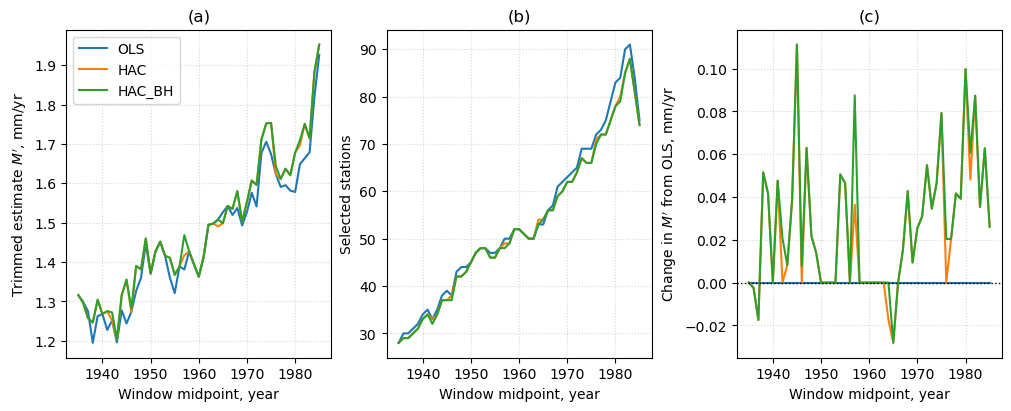

HAC maximum absolute change in trimmed estimate: 0.11118887236461772 mm/yr; changed stations range: 0 5
HAC_BH maximum absolute change in trimmed estimate: 0.11118887236461772 mm/yr; changed stations range: 0 5
Saved to: C:\Users\User\work\IPGP\Climate\bin\observational_hac_results\export_20261124_192419_149811


In [14]:
from datetime import datetime
export_dir = OUTPUT_DIR/('export_'+datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
export_dir.mkdir(parents=True,exist_ok=False)
metadata = dict(config=CONFIG,data_hash=data_fingerprint(series),
                numpy=np.__version__,scipy=scipy.__version__)
(export_dir/'metadata.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')
final_stations.to_csv(export_dir/'final_station_decisions.csv',index=False)
final_summary.to_csv(export_dir/'final_estimates.csv',index=False)
if RUN_BANDWIDTH_CHECK:
    bandwidth_summary.to_csv(export_dir/'bandwidth_sensitivity.csv',index=False)
if RUN_ALL:
    all_stations.to_csv(export_dir/'all_station_decisions.csv',index=False)
    all_summary.to_csv(export_dir/'all_window_estimates.csv',index=False)
    fig = plot_comparison(all_summary,gamma=.25)
    fig.savefig(export_dir/'selection_sensitivity.jpg',dpi=600,bbox_inches='tight')
    fig.savefig(export_dir/'selection_sensitivity.pdf',bbox_inches='tight')
    plt.show()
    for method in ['HAC','HAC_BH']:
        g=all_summary[(all_summary.method==method)&np.isclose(all_summary.gamma,.25)]
        print(method,'maximum absolute change in trimmed estimate:',g.delta_M_vs_OLS.abs().max(),
              'mm/yr; changed stations range:',g.changed_vs_OLS.min(),g.changed_vs_OLS.max())
print('Saved to:',export_dir.resolve())


## 10. Reporting checklist
Report annual data, two-sided testing, p threshold and FDR level; the HAC kernel, bandwidth, finite-sample multiplier and approximate reference distribution; counts lost and gained per window; changes in $M'$; and bandwidth sensitivity. Use the station decision CSV to inspect consequential changes.

Correct the manuscript's earlier monthly/one-sided/0.05 description if these settings reproduce the observational calculation. A positive slope selected by a two-sided 0.01 test is not the same rule as a one-sided 0.01 test. Do not silently switch conventions.

For a separate check of the previously discussed 0.05-to-0.10 thresholds, change `pcrit` explicitly and save that run separately; keep the FDR level documented. HAC is appropriate for weakly dependent regression residuals; it does not turn random-walk level residuals into stationary noise. Inspect residual behaviour before assigning a general physical interpretation to these comparisons.

No empirical outputs are bundled: run with the same local PSMSL snapshot used for the paper.
